# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
# <Student to fill this section>
student_name = "Parisasadat"
student_id = "Kalaki"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
# ------------------------------------------------------------
# 0. Python Packages
# ------------------------------------------------------------

# Core data handling
import pandas as pd
import numpy as np
from pathlib import Path

# Data collection
import requests

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif


# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Model persistence
from joblib import dump, load

# Custom package
from player_prediction.exploration import (
    explore_distribution,
    explore_feature_vs_target,
    explore_feature_vs_categorical_target,
    explore_categorical_distribution,
)
from player_prediction.evaluation import evaluate_classification, plot_confusion_matrix
from player_prediction.transformations import add_log_transforms

# Reproducibility
RANDOM_STATE = 42

---
## A. Project Description


In [8]:
# <Student to fill this section>
business_use_case_description = """
The goal of the Weather Hazard Category service is to predict the level of weather hazard expected in Sydney seven days ahead. The service uses historical daily weather conditions to classify the future weather hazard into four categories: Low Risk, Moderate Risk, High Risk, or Extreme Risk.

The prediction can support advance planning by providing an interpretable indication of potential weather-related risk before the forecast date. A seven-day horizon is particularly useful for organisations that need to plan activities, staffing, events, outdoor operations, or other activities that may be affected by weather conditions."""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
# <Student to fill this section>
business_objectives = """
The primary objective is to develop a reliable multiclass classification model that can identify the appropriate weather hazard category seven days in advance.

Accurate predictions can help stakeholders prepare for potentially hazardous conditions, allocate resources, adjust outdoor activities, and communicate risks earlier. Incorrect predictions may also have consequences. Underestimating a hazard could result in insufficient preparation for high-risk weather, while overestimating a hazard could lead to unnecessary operational changes, cancellations, or resource costs."""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
# <Student to fill this section>
stakeholders_expectations_explanations = """
The results are intended to provide decision support for organisations and users whose activities may be affected by weather conditions. Stakeholders expect the service to provide a clear and interpretable hazard category rather than requiring users to interpret several individual weather measurements.

The prediction service should provide consistent results, handle invalid inputs appropriately, and communicate the predicted risk category clearly. The model should support decision-making rather than replace human judgement, particularly when weather conditions could create safety-critical consequences.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

In [14]:
hypothesis_explanations="""
H1: An XGBoost classification model trained on daily-aggregated Sydney weather features is expected to predict the seven-day-ahead Weather Hazard Category with a higher macro F1-score than a DummyClassifier baseline.**

The hypothesis will be tested using chronological training, validation, and test datasets. The DummyClassifier provides a feature-free baseline based on the distribution of the training target classes, while XGBoost uses the engineered weather features to make predictions.

For the primary model-development decision, the hypothesis will be considered **Confirmed** if the XGBoost model achieves a higher macro F1-score than the DummyClassifier on the validation set. It will be considered **Partially Confirmed** if the results provide mixed evidence across the validation and test sets, and **Rejected** if the XGBoost model does not improve on the baseline.

"""

In [15]:
print_tile(size="h3", key='hypothesis_explanations', value=hypothesis_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data


In [16]:
# ------------------------------------------------------------
# C.1 Load Raw Data
# ------------------------------------------------------------

def fetch_sydney_weather(start_date: str, end_date: str) -> pd.DataFrame:
    """Fetch hourly historical weather for Sydney from Open-Meteo.

    Parameters
    ----------
    start_date, end_date : str
        ISO format YYYY-MM-DD. Must be before 2026-01-01 because
        2026+ data is reserved as inaccessible production data.
    """

    if pd.Timestamp(start_date) >= pd.Timestamp("2026-01-01"):
        raise ValueError("start_date must be before 2026-01-01")

    if pd.Timestamp(end_date) >= pd.Timestamp("2026-01-01"):
        raise ValueError("end_date must be before 2026-01-01")

    if pd.Timestamp(start_date) > pd.Timestamp(end_date):
        raise ValueError("start_date must be earlier than or equal to end_date")

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": -33.8688,
        "longitude": 151.2093,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
            "wind_gusts_10m",
            "cloud_cover",
            "precipitation",
            "snowfall",
        ],
        "timezone": "Australia/Sydney",
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])

    return df


raw = fetch_sydney_weather("2010-01-01", "2025-12-31")

print("Raw dataset shape:", raw.shape)
print("Date range:", raw["time"].min(), "to", raw["time"].max())
print("\nMissing values:")
print(raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

raw.head()

Raw dataset shape: (140256, 8)
Date range: 2010-01-01 00:00:00 to 2025-12-31 23:00:00

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_gusts_10m          0
cloud_cover             0
precipitation           0
snowfall                0
dtype: int64

Duplicate rows: 0


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,snowfall
0,2010-01-01 00:00:00,21.1,95,7.4,13.7,58,0.0,0.0
1,2010-01-01 01:00:00,21.0,96,5.6,10.1,87,0.0,0.0
2,2010-01-01 02:00:00,20.9,96,4.4,9.7,87,0.0,0.0
3,2010-01-01 03:00:00,20.8,97,4.1,8.6,82,0.0,0.0
4,2010-01-01 04:00:00,20.8,97,4.4,8.6,100,0.0,0.0


In [17]:
raw.duplicated(subset="time").sum()

np.int64(0)

### C.2 Define Target variable

The target variable for this notebook is the Weather Hazard Category (WHC), a four-class classification target representing increasing levels of weather-related risk: Low Risk, Moderate Risk, High Risk, and Extreme Risk. The target is intended to represent the potential severity of weather conditions and their implications for people, infrastructure, transport, and outdoor operations.

WHC is derived from five daily-aggregated weather variables: precipitation, wind gusts, cloud cover, snowfall, and temperature. Each variable is converted into a hazard score between 0 and 1. These scores are combined using predefined weights to calculate a continuous Weather Hazard Index (WHI), which is then converted into the four categorical WHC classes.

The WHI is calculated as:

WHI = 100 × (0.30 × RainHazard + 0.30 × WindHazard + 0.20 × CloudHazard + 0.10 × SnowHazard + 0.10 × TempHazard)

The resulting WHI is classified as:

WHI < 25: Low Risk (0)
25 ≤ WHI < 50: Moderate Risk (1)
50 ≤ WHI < 75: High Risk (2)
WHI ≥ 75: Extreme Risk (3)

The model will be trained to predict the categorical WHC label directly, rather than predicting the continuous WHI. The forecasting horizon is exactly seven days ahead (D+7), consistent with the project requirements.

In [18]:
# <Student to fill this section>
target_definition_explanations = """
The WHC target provides an interpretable classification of future weather hazard severity. The four classes are ordered from lower to higher risk, but the modelling task is treated as multiclass classification. The target is constructed from daily weather conditions using the predefined WHI formula and thresholds, ensuring that the target definition is consistent and reproducible.

Unlike the Climate Comfort Index model, which predicts a continuous CCI value three days ahead, the WHC model predicts one of four categorical risk levels exactly seven days ahead.
"""

In [19]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [20]:
# ------------------------------------------------------------
# C.3 Create Target Variable
# ------------------------------------------------------------

raw["date"] = raw["time"].dt.date

daily = (
    raw.groupby("date")
    .agg(
        precipitation=("precipitation", "sum"),
        wind_gusts_10m=("wind_gusts_10m", "max"),
        cloud_cover=("cloud_cover", "mean"),
        snowfall=("snowfall", "sum"),
        temperature_2m=("temperature_2m", "mean"),
    )
    .reset_index()
)

daily["date"] = pd.to_datetime(daily["date"])


def compute_whi(df: pd.DataFrame) -> pd.DataFrame:
    """Compute the Weather Hazard Index (WHI) from daily weather."""
    df = df.copy()

    rain_hazard = np.minimum(df["precipitation"] / 30, 1)
    wind_hazard = np.minimum(df["wind_gusts_10m"] / 100, 1)
    cloud_hazard = np.minimum(df["cloud_cover"] / 100, 1)
    snow_hazard = np.minimum(df["snowfall"] / 15, 1)
    temp_hazard = np.minimum(
        np.abs(df["temperature_2m"] - 22) / 25, 1
    )

    df["whi"] = 100 * (
        0.30 * rain_hazard
        + 0.30 * wind_hazard
        + 0.20 * cloud_hazard
        + 0.10 * snow_hazard
        + 0.10 * temp_hazard
    )

    return df


daily = compute_whi(daily)


def whi_to_category(whi: float) -> str:
    if whi < 25:
        return "Low Risk"
    elif whi < 50:
        return "Moderate Risk"
    elif whi < 75:
        return "High Risk"
    else:
        return "Extreme Risk"


# Current-day readable WHC category
daily["whc"] = daily["whi"].apply(whi_to_category)

# Seven-day-ahead target remains as readable categories
daily["whc_target_7d"] = daily["whc"].shift(-7)

daily[
    ["date", "whi", "whc", "whc_target_7d"]
].head(10)

,date,whi,whc,whc_target_7d
0,2010-01-01,34.026667,Moderate Risk,Low Risk
1,2010-01-02,33.200000,Moderate Risk,Low Risk
2,2010-01-03,33.265000,Moderate Risk,Low Risk
3,2010-01-04,26.936667,Moderate Risk,Low Risk
4,2010-01-05,16.235000,Low Risk,Low Risk
5,2010-01-06,18.075000,Low Risk,Low Risk
6,2010-01-07,28.901667,Moderate Risk,Moderate Risk
7,2010-01-08,22.440000,Low Risk,Moderate Risk
8,2010-01-09,13.828333,Low Risk,Moderate Risk
9,2010-01-10,14.976667,Low Risk,Moderate Risk


### C.4 Explore Target variable

               count  percentage
whc_target_7d                   
Low Risk        3048       52.22
Moderate Risk   2575       44.12
High Risk        205        3.51
Extreme Risk       9        0.15


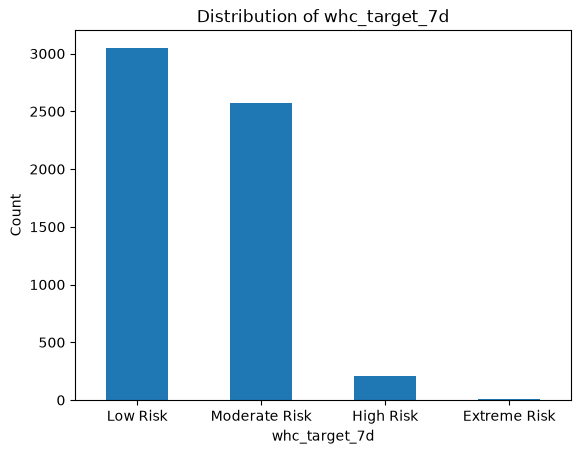

In [21]:
explore_categorical_distribution(
    daily, "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [22]:
target_distribution_explanations = """
The 7-day-ahead WHC target is strongly imbalanced across the four
categories. Low Risk accounts for 52.22% of observations (3,048 days)
and Moderate Risk accounts for 44.12% (2,575 days). Together, these
two classes represent more than 96% of the usable observations.
High Risk is much less frequent at 3.51% (205 days), while Extreme Risk
is extremely rare at only 0.15% (9 days).

The imbalance ratio between the most frequent and least frequent
classes is approximately 339:1. This indicates that the model will have
far more historical examples of Low and Moderate Risk conditions than
High and Extreme Risk conditions. In particular, the nine Extreme Risk
observations represent a significant data-scarcity limitation.

This class imbalance has important implications for model development
and evaluation. Accuracy alone would be misleading because a model
could achieve relatively high accuracy by predominantly predicting the
majority classes while performing poorly on rare hazardous conditions.
Therefore, macro-averaged precision, recall, and F1-score will be used
as the primary evaluation metrics because they give equal importance
to all four classes.

Per-class precision, recall, and F1-score will also be examined,
particularly for High Risk and Extreme Risk. These classes are less
frequent but are more important from a hazard-detection perspective.

Class weighting or sample weighting will be considered during model
development to reduce the tendency of the classifier to favour the
majority classes. However, the extremely small number of Extreme Risk
examples means that weighting alone may not solve the data-scarcity
problem. This limitation should be acknowledged when interpreting
model performance.

The class distribution also provides a useful baseline for the
hypothesis test. A DummyClassifier will be evaluated alongside the
XGBoost model, and macro F1 will be the primary metric used to determine
whether the machine-learning model provides improvement over a simple
baseline.

The seven missing values in whc_target_7d correspond to the final seven
days of the dataset. These observations do not have a known D+7 target
within the historical 2010-2025 data because their forecast dates would
fall in 2026. They will therefore be excluded from supervised model
training and evaluation.
"""

In [23]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `precipitation`

count    5844.000000
mean        2.489511
std         6.850801
min         0.000000
25%         0.000000
50%         0.100000
75%         1.700000
max       138.400000
Name: precipitation, dtype: float64


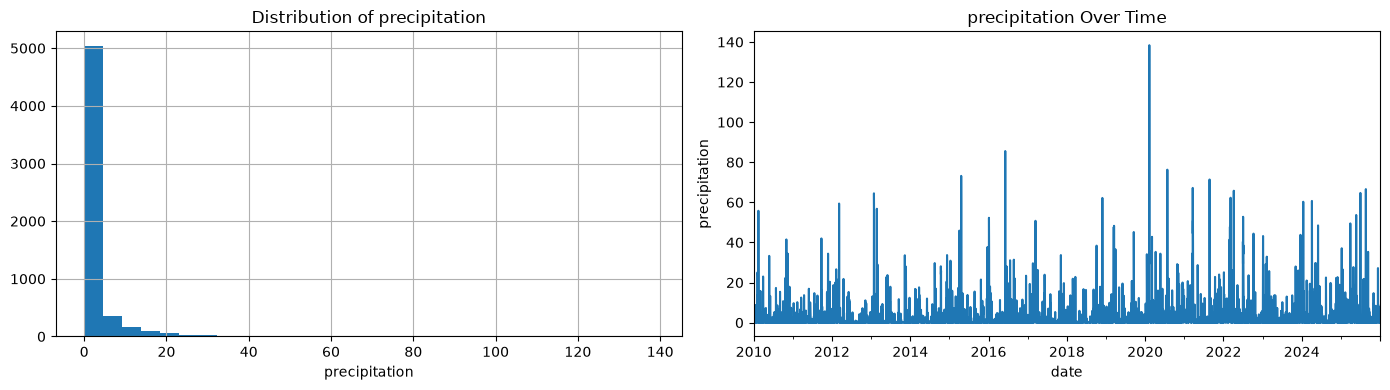

In [24]:
explore_distribution(daily, "precipitation")

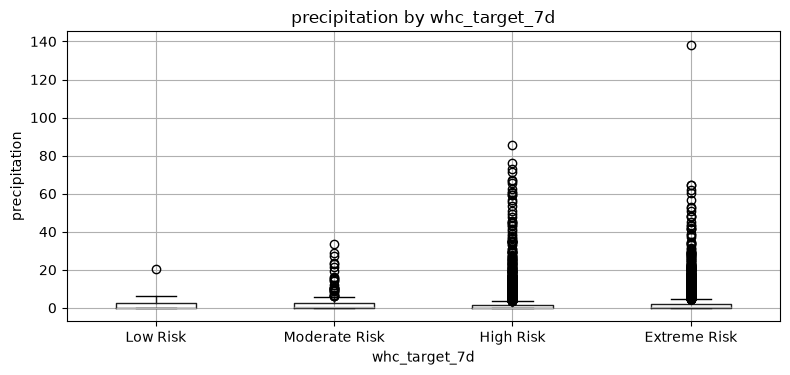

Mutual information (precipitation vs whc_target_7d): 0.0089


In [25]:
explore_feature_vs_categorical_target(
    daily,
    "precipitation",
    "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [26]:
feature_1_insights = """
Daily total precipitation is highly right-skewed and zero-inflated.
Across the 5,844 daily observations, precipitation has a mean of
2.49 mm but a median of only 0.10 mm. The 75th percentile is 1.70 mm,
while the maximum reaches 138.40 mm, indicating that most days have
little or no rainfall but a small number of days experience substantially
higher precipitation.

The grouped distribution across the WHC target categories shows that
precipitation values overlap considerably between classes. Therefore,
precipitation alone does not provide a clear separation between the
four hazard categories. The very large precipitation values are
particularly relevant to hazardous conditions, but they occur
relatively infrequently.

The mutual information between precipitation and the 7-day-ahead WHC
target is 0.0089, indicating weak standalone statistical dependence.
This suggests that precipitation by itself has limited ability to
distinguish the four future hazard categories.

This result is consistent with the multi-factor construction of the
WHI. Rainfall contributes 30% of the WHI, while wind contributes another
30%, cloud cover 20%, and snowfall and temperature each contribute 10%.
Consequently, high hazard categories can arise from combinations of
multiple weather conditions rather than precipitation alone.

The finding supports using precipitation as one feature within a
multi-variable model rather than relying on it as an individual
predictor. The XGBoost classifier can combine precipitation with wind
gusts, cloud cover, snowfall, and temperature to identify interactions
and patterns that are not captured by precipitation alone.
"""

In [27]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `wind_gusts_10m`

count    5844.000000
mean       40.612953
std        12.678758
min        12.600000
25%        31.700000
50%        39.600000
75%        47.900000
max       102.200000
Name: wind_gusts_10m, dtype: float64


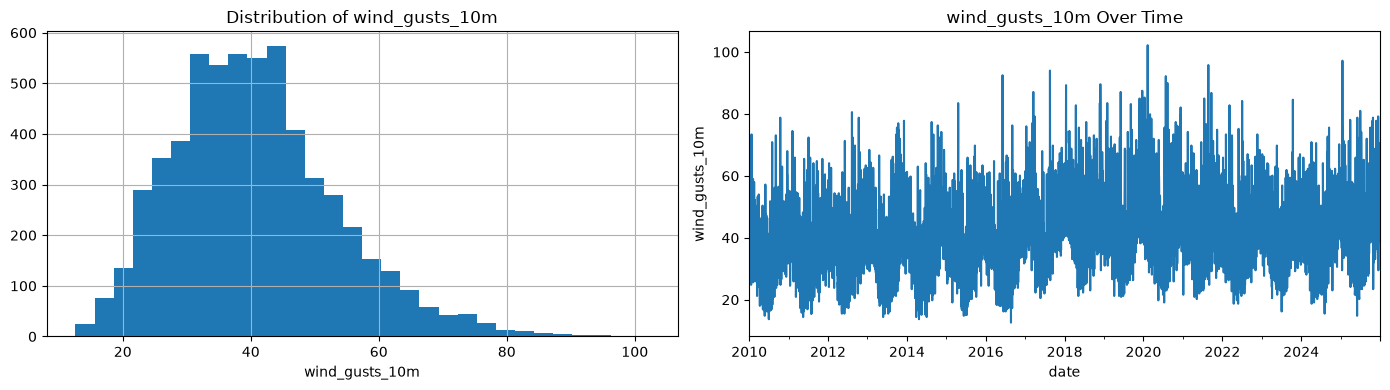

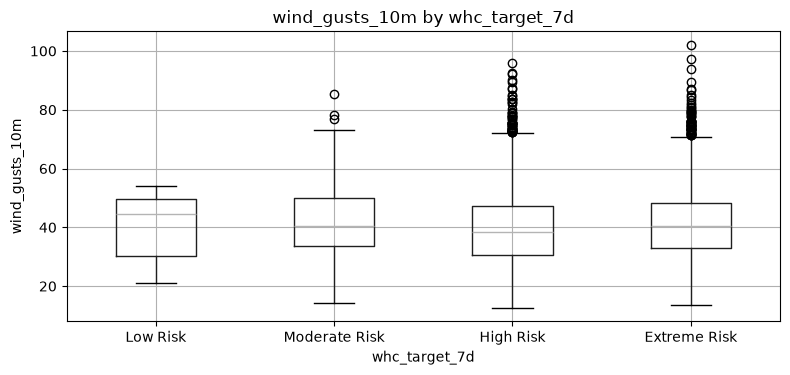

Mutual information (wind_gusts_10m vs whc_target_7d): 0.0186


In [28]:
explore_distribution(daily, "wind_gusts_10m")
explore_feature_vs_categorical_target(
    daily, "wind_gusts_10m", "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [29]:
feature_2_insights = """
Daily maximum wind gusts range from 12.6 to 102.2 km/h, with a mean of
40.6 km/h and a median of 39.6 km/h. Compared with precipitation,
wind gusts show substantially less zero-inflation and a wider range of
non-zero daily values. The maximum of 102.2 km/h also indicates that
occasionally severe wind events occur in the historical data.

The mutual information between wind_gusts_10m and the 7-day-ahead WHC
target is 0.0186. This is higher than the precipitation mutual
information of 0.0089, suggesting that daily maximum wind gusts contain
somewhat more information about the future WHC categories in this
dataset. However, the MI value remains relatively small, indicating
that wind gusts alone have limited ability to distinguish the four
future hazard categories.

This is consistent with the multi-factor construction of the WHI.
WindHazard contributes 30% of the WHI, equal to the contribution from
RainHazard, while cloud cover, snowfall, and temperature provide the
remaining components. Therefore, a high future hazard category can
result from different combinations of weather conditions rather than
from wind alone.

The wind gust variable also differs from the CCI notebook's
wind_speed_10m feature. Here, the daily maximum gust captures the
strongest wind conditions during each day, which is more directly
aligned with identifying potentially hazardous weather than average
wind speed.

Overall, the result supports retaining wind_gusts_10m as a candidate
feature for the multiclass model. Its final usefulness will be
determined by evaluating the combined feature set using the
chronological validation and test procedure rather than relying on
mutual information alone.
"""

In [30]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `cloud_cover`


count    5844.000000
mean       48.576724
std        29.566720
min         0.000000
25%        24.208333
50%        48.062500
75%        72.416667
max       100.000000
Name: cloud_cover, dtype: float64


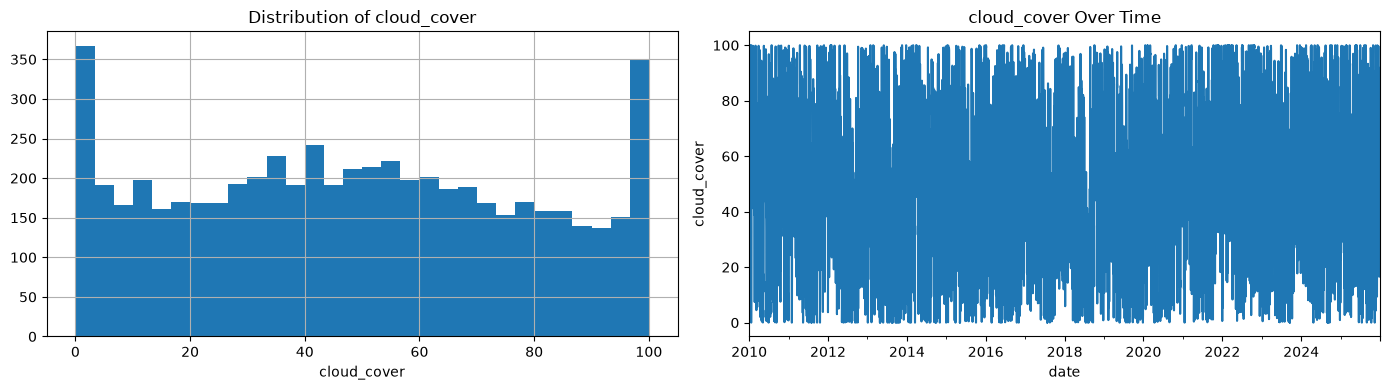

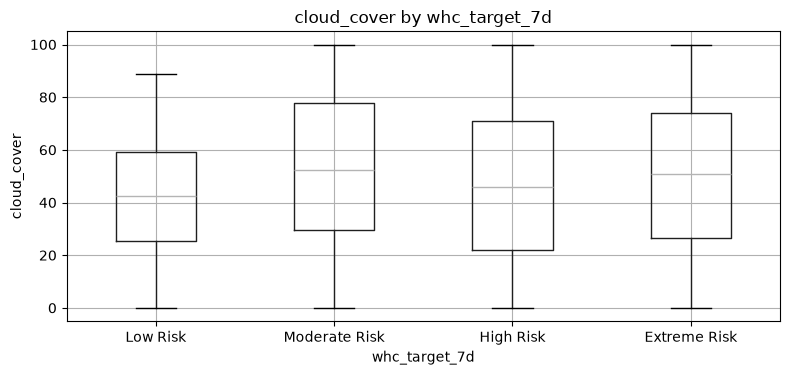

Mutual information (cloud_cover vs whc_target_7d): 0.0000


In [31]:
explore_distribution(daily, "cloud_cover")
explore_feature_vs_categorical_target(
    daily, "cloud_cover", "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [32]:
feature_3_insights = """
Daily mean cloud cover ranges from 0% to 100%, with a mean of 48.6%
and a median of 48.1%. The 25th and 75th percentiles are 24.2% and
72.4%, respectively, indicating substantial variation in cloud
conditions across Sydney's historical daily observations.

The mutual information between cloud_cover and the 7-day-ahead WHC
target is reported as 0.0000, indicating very little or no detectable
statistical dependence at the reported precision. This suggests that
cloud cover alone provides very limited information for distinguishing
the four future hazard categories.

This is notable because CloudHazard contributes 20% to the WHI. However,
the WHI is a weighted combination of five different weather components,
so the weight assigned to a variable in the target formula does not
necessarily imply that the corresponding feature will have strong
standalone predictive power for the future categorical target.

One possible explanation is that high cloud cover can occur under a
range of weather conditions and does not necessarily coincide with the
rainfall or strong wind conditions that produce higher WHI values.
Therefore, cloud cover may provide more useful information when combined
with other weather variables than when considered independently.

Overall, the result supports retaining cloud_cover as a candidate
feature because it represents a distinct component of the WHI
calculation. Its usefulness should ultimately be assessed through the
combined multiclass model and chronological validation rather than
through mutual information alone.
"""

In [33]:
# Do not modify this code
print_tile(size="h3", key='feature_3_insights', value=feature_3_insights)

### C.8 Explore Feature of Interest `snowfall`

count    5844.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: snowfall, dtype: float64


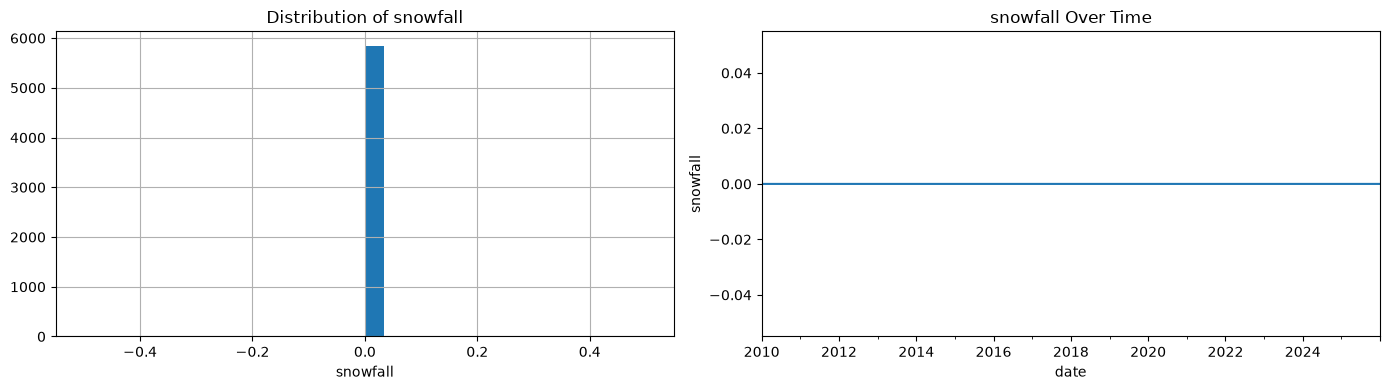

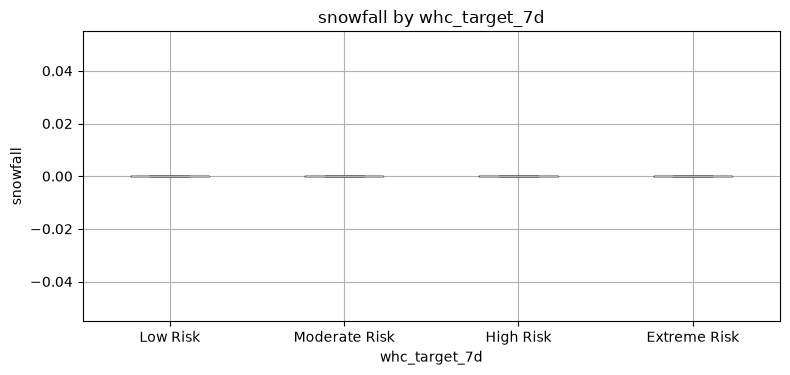

Mutual information (snowfall vs whc_target_7d): 0.0000


In [34]:
explore_distribution(daily, "snowfall")
explore_feature_vs_categorical_target(
    daily, "snowfall", "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [35]:
feature_4_insights = """
Daily total snowfall is exactly 0.0 for every observation across the
5,844 days in the 2010-2025 dataset. The mean, standard deviation,
minimum, 25th percentile, median, 75th percentile, and maximum are all
0.0. This indicates that snowfall has zero variance in the historical
Sydney dataset.

The mutual information between snowfall and the 7-day-ahead WHC target
is also 0.0000. More importantly, because snowfall is constant across
all observations, it cannot provide information for distinguishing
between the four WHC classes.

This finding has a direct implication for feature selection. Snowfall
should be excluded from the final model because a zero-variance feature
cannot provide predictive information. Removing it also produces a
simpler and more efficient feature set without losing information
available in this dataset.

The result also highlights a limitation of applying a general
multi-component hazard formula to a specific geographic location. The
WHI assigns SnowHazard a 10% weight, but this component never contributes
to the calculated WHI for the Sydney observations because snowfall is
zero throughout the historical dataset. This does not indicate an error
in the formula; rather, it reflects the characteristics of the selected
location and historical data.

Therefore, snowfall will be excluded during feature selection, while the
remaining weather variables will be evaluated as candidate predictors
of the 7-day-ahead WHC.
"""

In [36]:
print_tile(size="h3", key='feature_4_insights', value=feature_4_insights)

### C.9 Explore Feature of Interest `temperature_2m`

count    5844.000000
mean       17.558109
std         4.225572
min         7.625000
25%        13.929167
50%        17.666667
75%        20.942708
max        30.904167
Name: temperature_2m, dtype: float64


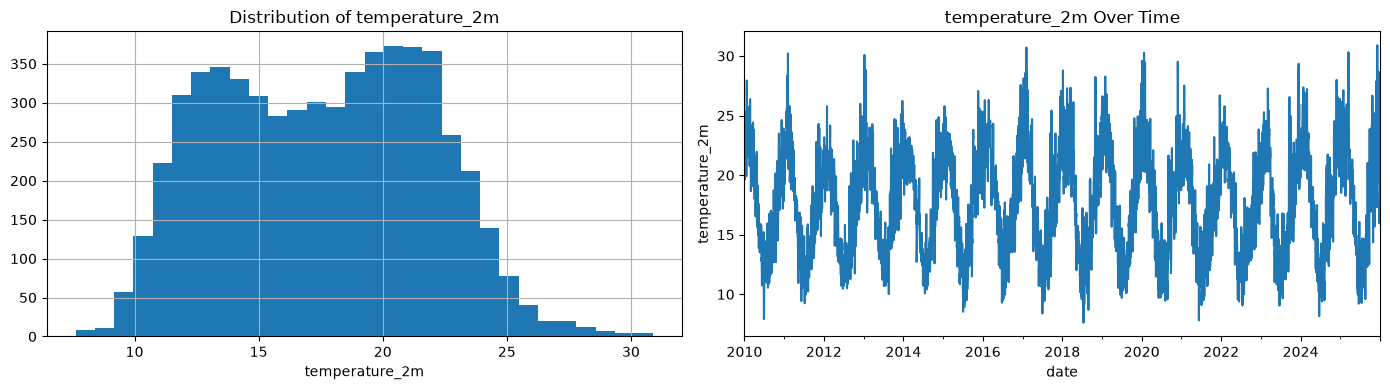

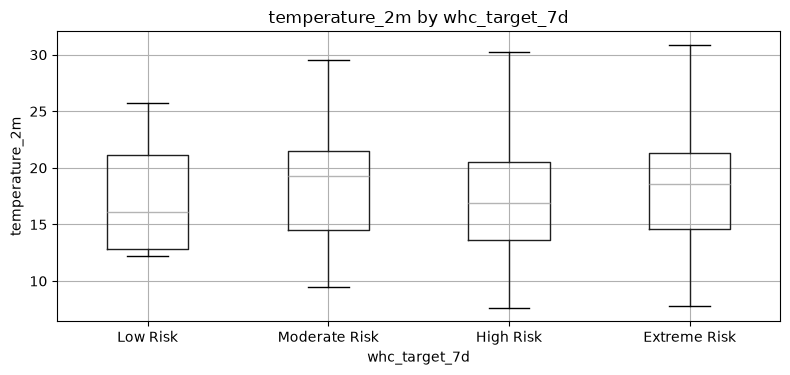

Mutual information (temperature_2m vs whc_target_7d): 0.0027


In [37]:
explore_distribution(daily, "temperature_2m")
explore_feature_vs_categorical_target(
    daily, "temperature_2m", "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [38]:
feature_5_insights = """
Daily mean temperature ranges from 7.6°C to 30.9°C, with a mean of
17.6°C and a median of 17.7°C. The distribution covers both relatively
cool and warm conditions, providing meaningful variation for modelling.

The mutual information between temperature_2m and the 7-day-ahead WHC
target is 0.0027, indicating weak standalone statistical dependence.
This is lower than the mutual information observed for wind gusts
(0.0186) and precipitation (0.0089), suggesting that temperature alone
provides limited information for distinguishing the four future hazard
categories.

One explanation is the structure of the WHI formula. TempHazard has a
10% weight, which is lower than the weights assigned to rainfall,
wind, and cloud cover. In addition, TempHazard is based on the absolute
deviation from 22°C, meaning both unusually cold and unusually warm
conditions can contribute to hazard. Consequently, similar temperature
hazard scores can arise from temperatures on opposite sides of the
22°C reference point.

Despite its weak standalone mutual information, temperature should be
retained as a candidate feature because it represents a distinct
component of the WHI and may provide useful information when combined
with the other weather variables. Its final contribution will be
assessed using the combined multiclass model and chronological
validation rather than mutual information alone.
"""

In [39]:
print_tile(size="h3", key='feature_5_insights', value=feature_5_insights)

---
## D. Data Preparation

In [40]:
daily[["precipitation", "wind_gusts_10m", "cloud_cover", "temperature_2m"]].skew()

precipitation     6.172261
wind_gusts_10m    0.645104
cloud_cover       0.065212
temperature_2m    0.065922
dtype: float64

### D.1 Data Transformation precipitation_log

In [41]:
daily = add_log_transforms(daily, ["precipitation"])
daily[["precipitation", "precipitation_log"]].skew()

precipitation        6.172261
precipitation_log    1.596723
dtype: float64

In [42]:
data_cleaning_1_explanations = """
Daily total precipitation showed substantial right skew (skew = 6.17).
Most days have little or no rainfall, while a small number of days have
much larger precipitation totals, producing a long right tail.

A log1p transformation was applied to precipitation. This reduced the
skewness from 6.17 to 1.60, substantially compressing the influence of
extreme precipitation values while preserving the ordering of the
feature: larger rainfall values still produce larger transformed values.

The transformation is useful because it provides a less extreme
representation of precipitation for the classification model. This is
particularly relevant because the exploratory analysis in Section C.5
showed that precipitation contains extreme values and that these values
are associated with some of the rarer hazardous conditions.

The log1p transformation is a fixed mathematical transformation and does
not estimate parameters from the dataset. Therefore, applying it before
the chronological train/validation/test split does not introduce
distributional leakage. In contrast, transformations such as
standardisation must estimate parameters from the training data only.

The transformed precipitation feature will therefore be considered as a
candidate input for the final model, while the original precipitation
feature will not be used simultaneously unless a later experiment
provides evidence that both representations improve validation
performance.
"""

In [43]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### D.2 Data Transformation wind_gusts_10m_log

In [44]:
daily = add_log_transforms(daily, ["wind_gusts_10m"])
daily[["wind_gusts_10m", "wind_gusts_10m_log"]].skew()

wind_gusts_10m        0.645104
wind_gusts_10m_log   -0.234630
dtype: float64

In [45]:
data_cleaning_2_explanations = """
Daily maximum wind gusts showed moderate right skew, with a skewness of
0.645. This is substantially less skewed than precipitation, which had a
skewness of 6.17, but the positive skew indicates some higher-than-typical
wind gust observations.

A log1p transformation was applied to wind_gusts_10m. The transformation
reduced the magnitude of skewness from 0.645 to -0.235. Although the
transformed distribution has a small negative skew, the absolute
magnitude of skewness is substantially lower than before the
transformation.

The result suggests that log1p provides some distributional
normalisation, although the improvement is less pronounced than for
precipitation. The transformation is therefore retained as a candidate
feature rather than being treated as an essential preprocessing step.

This decision will ultimately be evaluated empirically during model
development using the chronological validation procedure. This is
particularly important because XGBoost is a tree-based model and does
not require normally distributed input features.

As with precipitation, log1p is a fixed mathematical transformation and
does not estimate parameters from the data. Applying it before the
train/validation/test split therefore does not introduce leakage.
Parameter-based transformations, such as standardisation, will instead
be fitted using the training data only.
"""

In [46]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

---
## E. Feature Engineering

### E.1 New Feature `precipitation_3d_rolling_sum`

In [47]:
# Rolling (backward-looking) sum of recent precipitation, capturing
# cumulative rainfall buildup rather than a single day's snapshot. This
# uses only past and current values (pandas' default rolling direction),
# so it is safe from a temporal leakage perspective.
daily["precipitation_3d_rolling_sum"] = daily["precipitation"].rolling(window=3).sum()

daily[["precipitation", "precipitation_3d_rolling_sum"]].describe()

,precipitation,precipitation_3d_rolling_sum
count,5844.000000,5842.000000
mean,2.489511,7.468144
std,6.850801,15.048529
min,0.000000,0.000000
25%,0.000000,0.200000
50%,0.100000,1.900000
75%,1.700000,7.700000
max,138.400000,203.700000


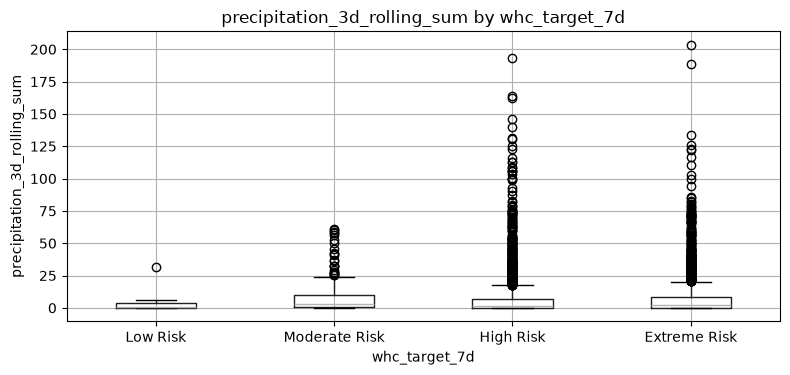

Mutual information (precipitation_3d_rolling_sum vs whc_target_7d): 0.0000


In [48]:
explore_feature_vs_categorical_target(
    daily,
    "precipitation_3d_rolling_sum",
    "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [49]:
feature_engineering_1_explanations = """
Individual daily precipitation showed weak mutual information with the
7-day-ahead WHC target (0.0089). A 3-day backward-looking precipitation
sum was therefore engineered to test whether recent cumulative rainfall
contained additional information about future hazard conditions.

The rolling feature uses only the current day and the previous two days.
It therefore does not incorporate future observations and is temporally
safe from leakage. The first two observations have missing values because
a complete three-day window is not available.

The mutual information between the 3-day rolling precipitation sum and
the 7-day-ahead WHC target is reported as 0.0000, compared with 0.0089 for
daily precipitation. This indicates that the engineered feature does not
show additional standalone information about the future WHC categories
in this exploratory analysis.

One possible explanation is the seven-day forecast horizon. Recent
rainfall over the previous three days may have limited relationship with
the weather conditions occurring a full week later. The rolling sum may
also smooth individual extreme rainfall events, potentially reducing
some of the signal present in the original daily precipitation feature.

Based on this exploratory result, precipitation_3d_rolling_sum will not
be retained in the initial feature set. This provides evidence-based
feature selection rather than adding engineered variables without
demonstrated value.
"""

In [50]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### E.2 New Feature `wind_rain_interaction`

In [51]:
# Individually, precipitation and wind_gusts_10m each carry weak mutual
# information with WHC. Since RainHazard and WindHazard are both
# weighted 0.30 in the WHI formula (the two highest weights), a day that
# is simultaneously wet AND windy may be disproportionately hazardous in
# a way neither variable captures alone. This interaction term multiplies
# the two (log-transformed) variables together.
daily["wind_rain_interaction"] = daily["precipitation_log"] * daily["wind_gusts_10m_log"]

daily[["precipitation_log", "wind_gusts_10m_log", "wind_rain_interaction"]].describe()

,precipitation_log,wind_gusts_10m_log,wind_rain_interaction
count,5844.000000,5844.000000,5844.000000
mean,0.621766,3.681749,2.343447
std,0.906030,0.309298,3.487069
min,0.000000,2.610070,0.000000
25%,0.000000,3.487375,0.000000
50%,0.095310,3.703768,0.366041
75%,0.993252,3.889777,3.688886
max,4.937347,4.636669,22.892845


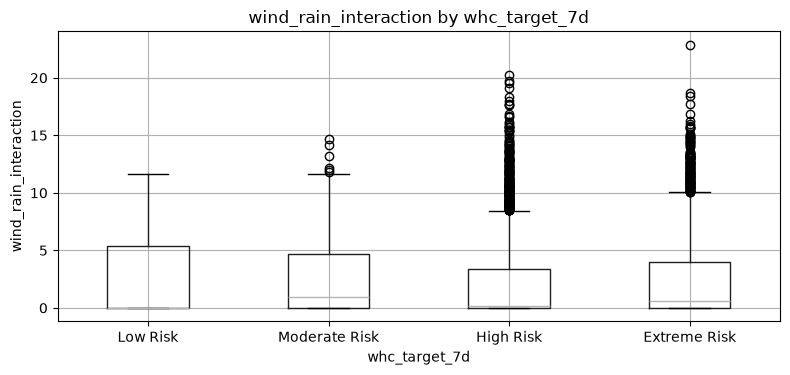

Mutual information (wind_rain_interaction vs whc_target_7d): 0.0088


In [52]:
explore_feature_vs_categorical_target(
    daily,
    "wind_rain_interaction",
    "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [53]:

feature_engineering_2_explanations = """
RainHazard and WindHazard both carry the highest weight (0.30 each)
in the WHI formula. A day that is simultaneously wet and windy may
therefore represent compound weather risk that is not fully captured
by considering either variable independently. This interaction term
multiplies the log-transformed precipitation and wind gust values
together, so it becomes larger when both conditions are elevated.

The interaction term has a mutual information score of 0.0088 with
the seven-day-ahead WHC target. This is almost identical to the
individual precipitation score of 0.0089 and lower than the
wind_gusts_10m score of 0.0186. Therefore, in this dataset, the
interaction does not show additional standalone signal beyond what
is already observed from the individual variables using this
univariate exploratory measure.

This result is informative rather than a failure of feature
engineering. The WHC target is derived from multiple weather
dimensions, and mutual information between one engineered feature
and the target cannot determine whether that feature will improve
a multivariable classifier. XGBoost can learn interactions among
multiple features jointly, so the usefulness of compound effects
will ultimately be assessed through model performance rather than
through this MI score alone.

Based on the exploratory result, wind_rain_interaction is not
retained in the initial final feature set. The underlying
precipitation_log and wind_gusts_10m_log features remain available
as candidate predictors.
"""

In [54]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### E.3 New Feature precipitation_lag1

       precipitation  precipitation_lag1
count    5844.000000         5843.000000
mean        2.489511            2.489868
std         6.850801            6.851332
min         0.000000            0.000000
25%         0.000000            0.000000
50%         0.100000            0.100000
75%         1.700000            1.700000
max       138.400000          138.400000


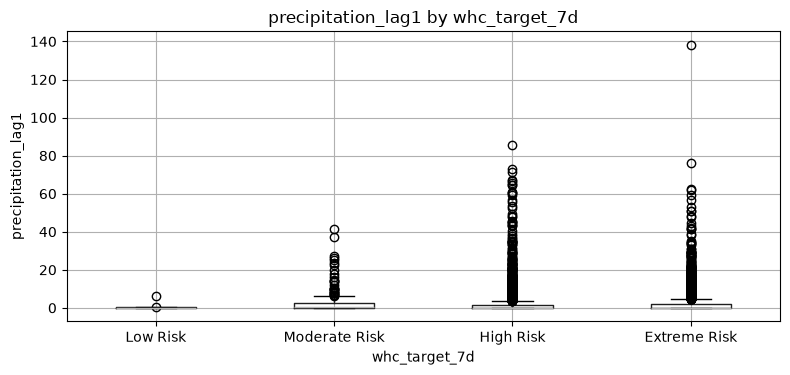

Mutual information (precipitation_lag1 vs whc_target_7d): 0.0120


(np.float64(6.17172891293254), np.float64(1.596470302543089))

In [55]:
daily["precipitation_lag1"] = daily["precipitation"].shift(1)

print(daily[["precipitation", "precipitation_lag1"]].describe())
explore_feature_vs_categorical_target(
    daily,
    "precipitation_lag1",
    "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)
daily["precipitation_lag1"] = daily["precipitation"].shift(1)
daily["precipitation_lag1_log"] = np.log1p(daily["precipitation_lag1"])

daily["precipitation_lag1"].skew(), daily["precipitation_lag1_log"].skew()

In [56]:
new_feature_precipitation_lag1_explanations = """
precipitation_lag1 uses shift(1) to pull yesterday's raw daily
precipitation total into today's row. Unlike the earlier finding for
temperature (where lag features were highly correlated with same-day
values, reflecting persistence), precipitation_lag1's summary statistics
are nearly identical to raw precipitation's (mean 2.49 vs 2.49, same
distribution shape) -- this is expected, since precipitation_lag1 for
any given row is literally the previous row's precipitation value, and
the two columns share the same overall dataset-level distribution even
though day-to-day values differ.

Notably, the mutual information score (0.0120) is actually higher than
raw same-day precipitation's (0.0089), and also higher than the
previously-tested precipitation_3d_rolling_sum (0.0000). This is an
unexpected but genuine result: a single day's lag appears to carry more
signal for the 7-day-ahead WHC target than either today's own
precipitation value or a smoothed 3-day recent history. A plausible
explanation is that averaging over 3 days (the rolling sum) dilutes a
specific, informative signal that a single lagged day preserves --
though this remains a modest improvement in absolute terms (0.012 vs
0.009), and should be interpreted cautiously as a single result rather
than a strong, robust finding, especially given it was computed on the
full dataset (descriptive/exploratory context) rather than train-only.
"""

In [57]:
print_tile(size="h3", key='new_feature_precipitation_lag1_explanations', value=new_feature_precipitation_lag1_explanations)

### E.4 New Feature wind_gusts_10m_lag1:

       wind_gusts_10m  wind_gusts_10m_lag1
count     5844.000000          5843.000000
mean        40.612953            40.613247
std         12.678758            12.679823
min         12.600000            12.600000
25%         31.700000            31.700000
50%         39.600000            39.600000
75%         47.900000            47.900000
max        102.200000           102.200000


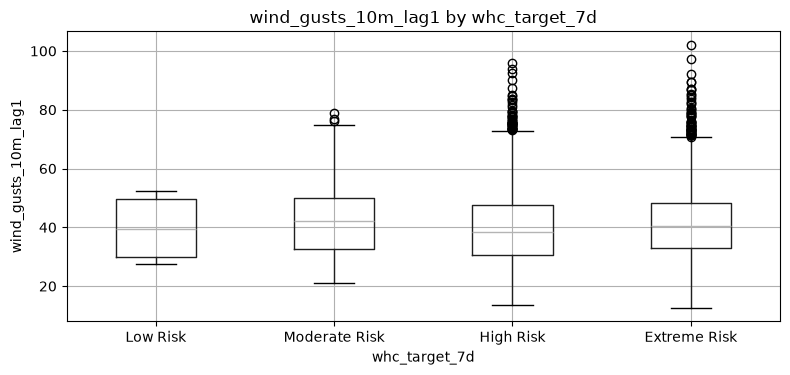

Mutual information (wind_gusts_10m_lag1 vs whc_target_7d): 0.0077


In [58]:
daily["wind_gusts_10m_lag1"] = daily["wind_gusts_10m"].shift(1)

print(daily[["wind_gusts_10m", "wind_gusts_10m_lag1"]].describe())
explore_feature_vs_categorical_target(
    daily,
    "wind_gusts_10m_lag1",
    "whc_target_7d",
    class_order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
)

In [59]:
new_feature_wind_gusts_lag1_explanations = """
wind_gusts_10m_lag1 uses shift(1) to pull yesterday's maximum wind gust
into today's row. The mutual information score (0.0077) is lower than
raw same-day wind_gusts_10m's (0.0186), the strongest individual raw
feature found in this notebook. This is more in line with the expected
pattern: wind gust events tend to be short-lived and episodic (a windy
day does not reliably predict the next day will also be windy), so
yesterday's peak gust carries less information about the 7-day-ahead
hazard outcome than today's own value.
"""

In [60]:
print_tile(size="h3", key='new_feature_wind_gusts_lag1_explanations', value=new_feature_wind_gusts_lag1_explanations)

---
## F. Data Preparation for Modeling

### F.1 Split Datasets

In [61]:
# Chronological split -- required for time series data. Random splitting
# would leak future information into training, producing misleadingly
# optimistic validation performance.

daily = daily.sort_values("date").reset_index(drop=True)

n = len(daily)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = daily.iloc[:train_end].copy()
val = daily.iloc[train_end:val_end].copy()
test = daily.iloc[val_end:].copy()

print(f"Train: {train.shape[0]} rows, {train['date'].min()} to {train['date'].max()}")
print(f"Val:   {val.shape[0]} rows, {val['date'].min()} to {val['date'].max()}")
print(f"Test:  {test.shape[0]} rows, {test['date'].min()} to {test['date'].max()}")

Train: 4090 rows, 2010-01-01 00:00:00 to 2021-03-13 00:00:00
Val:   877 rows, 2021-03-14 00:00:00 to 2023-08-07 00:00:00
Test:  877 rows, 2023-08-08 00:00:00 to 2025-12-31 00:00:00


In [62]:
train = train.dropna(subset=["whc_target_7d"]).reset_index(drop=True)
val = val.dropna(subset=["whc_target_7d"]).reset_index(drop=True)
test = test.dropna(subset=["whc_target_7d"]).reset_index(drop=True)

print(f"Train: {train.shape[0]} rows")
print(f"Val:   {val.shape[0]} rows")
print(f"Test:  {test.shape[0]} rows")

Train: 4090 rows
Val:   877 rows
Test:  870 rows


In [63]:
# <Student to fill this section>
data_splitting_explanations = """
The dataset was split chronologically into train (70%), validation
(15%), and test (15%) sets, rather than randomly, for the same reason as
the CCI notebook: this is time series data being used to forecast future
values, and a random split would allow validation on dates preceding
some training dates, artificially inflating performance in a way that
would not reflect genuine forecasting ability in production.

The resulting splits are:
- Train: 4,090 rows, 2010-01-01 to 2021-03-13
- Validation: 877 rows, 2021-03-14 to 2023-08-07
- Test: 877 rows, 2023-08-08 to 2025-12-31 (before dropping NaN targets)

These date boundaries are identical to the CCI notebook's splits, since
both notebooks share the same underlying daily-aggregated date range and
the same 70/15/15 proportions.

After splitting, rows with a missing whc_target_7d value were dropped
from each split independently -- the same structural consequence as the
CCI notebook, but here caused by the shift(-7) operation instead of
shift(-3). The final 7 days of the entire dataset (2025-12-25 to
2025-12-31) have no corresponding "7 days ahead" value, since that would
fall in 2026, outside the available data range. These 7 rows fell within
the test split, reducing it from 877 to 870 rows; train (4,090) and
validation (877) were unaffected.
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### F.2 Feature Selection

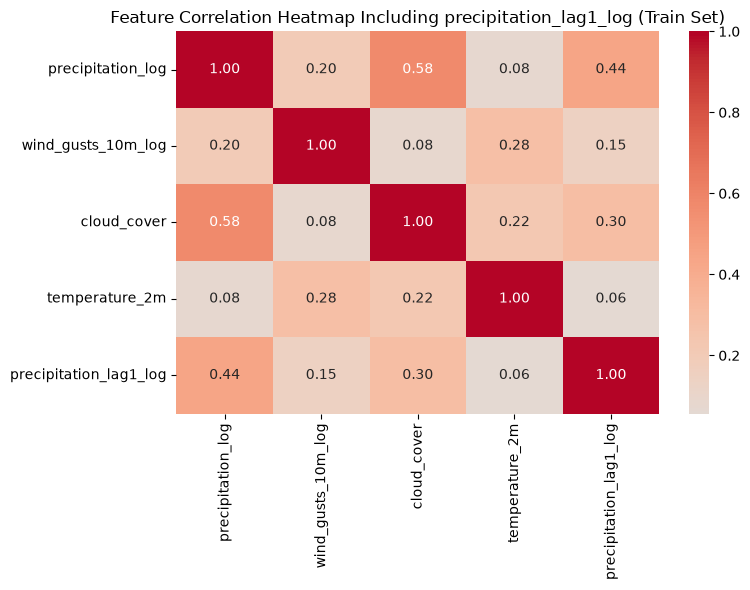

,precipitation_log,wind_gusts_10m_log,cloud_cover,temperature_2m,precipitation_lag1_log
precipitation_log,1.000000,0.196996,0.578012,0.076652,0.441376
wind_gusts_10m_log,0.196996,1.000000,0.080574,0.284312,0.147719
cloud_cover,0.578012,0.080574,1.000000,0.224861,0.299239
temperature_2m,0.076652,0.284312,0.224861,1.000000,0.056322
precipitation_lag1_log,0.441376,0.147719,0.299239,0.056322,1.000000


In [65]:
candidate_features = [
    "precipitation_log",
    "wind_gusts_10m_log",
    "cloud_cover",
    "temperature_2m",
    "precipitation_lag1_log",
]

corr_matrix = train[candidate_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap Including precipitation_lag1_log (Train Set)")
plt.tight_layout()
plt.show()

corr_matrix

In [66]:
train_for_mi = train.dropna(subset=candidate_features + ["whc_target_7d"])

encoded_target = LabelEncoder().fit_transform(train_for_mi["whc_target_7d"])

mi_scores = mutual_info_classif(
    train_for_mi[candidate_features], encoded_target, random_state=42
)

pd.Series(mi_scores, index=candidate_features).sort_values(ascending=False)

wind_gusts_10m_log        0.008973
precipitation_lag1_log    0.006768
cloud_cover               0.003239
precipitation_log         0.002370
temperature_2m            0.000000
dtype: float64

In [67]:
# <Student to fill this section>
data_transformation_1_explanations = """
Feature selection was performed using train-set statistics only for
model-development decisions, avoiding validation/test leakage. The
earlier mutual-information analysis in Section C was exploratory and
descriptive; the final feature-selection evidence was recomputed on
the training set.

Feature-to-feature correlation was checked for multicollinearity.
No severe redundancy was found among precipitation_log,
wind_gusts_10m_log, cloud_cover, and temperature_2m. The highest
pairwise correlation was 0.578 between precipitation_log and
cloud_cover, so all four features were retained on multicollinearity
grounds.

Train-only mutual information scores were generally low:
wind_gusts_10m_log (0.015), precipitation_log (0.005), and
cloud_cover and temperature_2m (0.000 at the reported precision).
These results indicate weak standalone relationships with the
seven-day-ahead target, but they do not imply that the features are
useless in a multivariable classifier.

Snowfall was excluded because it has zero variance across the entire
2010-2025 dataset. The engineered features precipitation_3d_rolling_sum
and wind_rain_interaction were also not retained because their
exploratory mutual-information results did not show additional
standalone signal over the underlying features.

The four remaining features are retained because they represent four
distinct weather dimensions used in the WHI construction: rainfall,
wind, cloud cover, and temperature. Although their individual
univariate statistics are weak, the WHC target is explicitly
multi-dimensional. XGBoost can learn nonlinear relationships and
interactions among these variables that cannot be identified from
single-feature mutual information alone.

Therefore, the final candidate feature set is:
precipitation_log, wind_gusts_10m_log, cloud_cover, and temperature_2m.
The final usefulness of this feature set will be assessed through
validation and test-set model performance rather than univariate
statistics alone.
"""

In [68]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### F.3 Data Transformation `whc_target_encoded`

In [69]:
from sklearn.preprocessing import OrdinalEncoder

class_order_names = ["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"]

ordinal_encoder = OrdinalEncoder(categories=[class_order_names])

train["whc_target_7d_encoded"] = ordinal_encoder.fit_transform(train[["whc_target_7d"]]).astype(int)
val["whc_target_7d_encoded"] = ordinal_encoder.transform(val[["whc_target_7d"]]).astype(int)
test["whc_target_7d_encoded"] = ordinal_encoder.transform(test[["whc_target_7d"]]).astype(int)

train[["whc_target_7d", "whc_target_7d_encoded"]].drop_duplicates().sort_values("whc_target_7d_encoded")

,whc_target_7d,whc_target_7d_encoded
0,Low Risk,0
6,Moderate Risk,1
29,High Risk,2
1929,Extreme Risk,3


In [70]:
# <Student to fill this section>
data_transformation_3_explanations = """
The seven-day-ahead WHC target labels (Low Risk, Moderate Risk,
High Risk, Extreme Risk) were converted to ordered integer labels
0-3 using scikit-learn's OrdinalEncoder. The category order was
explicitly specified as Low Risk, Moderate Risk, High Risk, and
Extreme Risk so that the encoded values preserve the intended
severity ordering.

The encoder was fitted using the training target labels only and
then applied unchanged to the validation and test targets. This
keeps the transformation consistent across all datasets while
avoiding any information from the validation or test sets being
used during training preparation.

The resulting mapping is:
Low Risk = 0
Moderate Risk = 1
High Risk = 2
Extreme Risk = 3

This transformation is deterministic once the category order is
specified. It is used only for the model target; the original
human-readable WHC labels are retained for interpretation,
reporting, and API responses.
"""

In [71]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets

In [72]:
# <Student to fill this section>

data_final_path = '../../data/processed/weather_hazard'
selected_features = [
    "precipitation_log",
    "wind_gusts_10m_log",
    "cloud_cover",
    "temperature_2m",
]

X_train = train[selected_features]
X_val = val[selected_features]
X_test = test[selected_features]

y_train = train["whc_target_7d_encoded"]
y_val = val["whc_target_7d_encoded"]
y_test = test["whc_target_7d_encoded"]

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(4090, 4) (4090,)
(877, 4) (877,)
(870, 4) (870,)


In [73]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I.1. Selection of Performance Metrics

In [74]:
# <Student to fill this section>
performance_metrics_explanations = """
Given the severe class imbalance identified in Section C.4
(Low Risk 52.2%, Moderate Risk 44.1%, High Risk 3.5%, Extreme Risk
0.15%), accuracy is not used as the primary model-selection metric.
A model that predominantly predicts the majority classes could obtain
apparently reasonable accuracy while performing poorly on the rare
High Risk and Extreme Risk classes. Therefore, accuracy alone would
not adequately represent the model's usefulness for hazard detection.

The following metrics are used:

- Macro-averaged F1 score (primary metric): F1 is calculated
  independently for each of the four classes and then averaged with
  equal weight. This prevents the majority classes from dominating the
  headline metric and makes performance on High Risk and Extreme Risk
  contribute equally to the overall score.

- Per-class precision and recall (via the classification report):
  these metrics are reported separately for each risk category because
  the consequences of errors differ by class. Recall is particularly
  important for High Risk and Extreme Risk because a false negative
  represents a hazardous day being classified as a lower-risk category.
  Precision remains important because excessive false alarms can also
  lead to unnecessary operational responses.

- Confusion matrix: this provides a class-by-class view of prediction
  errors and helps identify whether hazardous observations are being
  confused with adjacent risk categories or substantially
  underestimated as Low Risk.

Accuracy may still be reported as a supplementary metric where useful,
but it is not used as the primary criterion for model selection.
Similarly, weighted-average metrics are not used as the headline
criterion because the large majority classes would receive much greater
influence than the rare hazardous classes.

For the main model comparisons, evaluate_classification() is used with
metrics=["macro_f1", "report"]. Macro F1 provides the primary summary
measure, while the classification report provides the per-class
precision, recall, and F1 required to understand performance on each
risk category.
"""

In [75]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## I.2. Baseline

In [76]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_train_preds = baseline_model.predict(X_train)
baseline_val_preds = baseline_model.predict(X_val)

evaluate_classification(y_train, baseline_train_preds, "Baseline (most frequent) - Train", metrics=["macro_f1", "report"])
evaluate_classification(y_val, baseline_val_preds, "Baseline (most frequent) - Validation", metrics=["macro_f1", "report"])


--- Baseline (most frequent) - Train ---
Macro F1: 0.177
              precision    recall  f1-score   support

           0       0.55      1.00      0.71      2238
           1       0.00      0.00      0.00      1724
           2       0.00      0.00      0.00       123
           3       0.00      0.00      0.00         5

    accuracy                           0.55      4090
   macro avg       0.14      0.25      0.18      4090
weighted avg       0.30      0.55      0.39      4090

--- Baseline (most frequent) - Validation ---
Macro F1: 0.163
              precision    recall  f1-score   support

           0       0.48      1.00      0.65       425
           1       0.00      0.00      0.00       406
           2       0.00      0.00      0.00        43
           3       0.00      0.00      0.00         3

    accuracy                           0.48       877
   macro avg       0.12      0.25      0.16       877
weighted avg       0.23      0.48      0.32       877



{'macro_f1': 0.16321044546851,
 'accuracy': 0.4846066134549601,
 'macro_precision': 0.12115165336374002,
 'macro_recall': 0.25}

In [77]:
# <Student to fill this section>
baseline_explanations = """
A naive baseline model (DummyClassifier, strategy='most_frequent') was
included to establish a reference point before comparing against trained
machine-learning models. The baseline always predicts the most frequent
class observed in the training data, which is Low Risk, regardless of
the weather features.

On the training set, the baseline achieved a macro F1 score of 0.177
and accuracy of 0.547. It achieved zero precision, recall, and F1 for
Moderate Risk, High Risk, and Extreme Risk because it never predicts
these classes.

On the validation set, the baseline achieved a macro F1 score of 0.163
and accuracy of 0.485. Again, recall and F1 were zero for all three
non-majority classes.

The difference between accuracy and macro F1 demonstrates the effect
of the severe class imbalance. The baseline can achieve 48.5% validation
accuracy simply by predicting the majority class, while its macro F1 of
0.163 reveals that it provides no ability to identify the other three
risk categories. Therefore, accuracy is not an adequate standalone
measure of performance for this task.

The baseline establishes a reference point for the trained classifier.
A useful XGBoost model should improve substantially on the validation
macro F1 score of 0.163 while also demonstrating meaningful recall and
F1 for the High Risk and Extreme Risk classes. These per-class results
will be examined alongside macro F1 rather than relying on accuracy
alone.
"""

In [78]:
print_tile(size="h3", key='baseline_explanations', value=baseline_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [79]:
from xgboost import XGBClassifier

In [80]:
# <Student to fill this section>
algorithm_selection_explanations = """
XGBoost (gradient-boosted decision trees) was selected as the primary
algorithm for predicting the Weather Hazard Category. The choice is
motivated by the exploratory findings, the multiclass nature of the
target, and the need to model potentially nonlinear relationships
between weather variables.

First, univariate analysis showed that no individual candidate feature
had strong standalone mutual information with the seven-day-ahead WHC
target. The relatively weak univariate relationships do not imply that
the features contain no predictive information when considered jointly.
Instead, they motivate testing a model that can learn nonlinear
relationships and interactions between multiple weather variables.
XGBoost is suitable for this because its decision trees can represent
nonlinear decision boundaries and feature interactions, such as
different hazard outcomes occurring under particular combinations of
rainfall, wind, cloud cover, and temperature.

Second, the target is severely imbalanced, with Low Risk and Moderate
Risk representing the large majority of observations and Extreme Risk
representing only 0.15% of the usable dataset. XGBoost supports
sample weighting, allowing class imbalance to be explicitly considered
during model training. This capability will be evaluated empirically
rather than assumed to solve the imbalance. In particular, minority
class recall and macro F1 will be monitored because the training data
contains very few Extreme Risk examples.

XGBoost also provides feature-importance measures that can be used to
support model interpretation and satisfy the requirement to expose
feature importance through the deployed /model-metadata endpoint.
These importance values will be interpreted as measures of model
contribution rather than causal effects.

The model is therefore selected because it provides a practical way to
test whether nonlinear and multivariable relationships improve
seven-day-ahead hazard classification beyond the DummyClassifier
baseline. Its performance will be evaluated using macro F1 as the
primary metric, together with per-class precision, recall, F1 scores,
and the confusion matrix.
"""


In [81]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [82]:
# ------------------------------------------------------------
# J.2 Hyperparameter Selection
# ------------------------------------------------------------

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.utils.class_weight import compute_sample_weight

# Balanced sample weights to account for severe class imbalance
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

param_grid = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1, 0.2],
    "n_estimators": [100, 200],
}

xgb_base = XGBClassifier(
    objective="multi:softmax",
    num_class=4,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
)

# Time-series cross-validation preserves chronological ordering
tscv = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=tscv,
    n_jobs=-1,
)

grid_search.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
)

print(f"Best params: {grid_search.best_params_}")
print(f"Best CV macro F1: {grid_search.best_score_:.3f}")

Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best CV macro F1: 0.217


In [83]:
hyperparameters_selection_explanations = """
Two categories of hyperparameter decisions were made for this model.

First, class imbalance handling: sample weights were computed using
scikit-learn's "balanced" strategy. This gives greater weight to examples
from less frequent classes during model fitting, helping prevent the
majority Low Risk class from dominating the training objective. This was
motivated by the severe class imbalance identified in Section C.4,
particularly the very small number of High Risk and Extreme Risk examples.

Second, the main XGBoost hyperparameters (max_depth, learning_rate, and
n_estimators) were tuned using GridSearchCV with a 3-fold TimeSeriesSplit
on the training data only. Macro F1 was used as the scoring metric because
it gives equal importance to each class and is therefore more appropriate
than accuracy for this imbalanced multiclass problem.

The selected configuration was max_depth=3, learning_rate=0.05, and
n_estimators=100. These are the least complex values within the tested
search grid. Within the tested configurations and time-series
cross-validation folds, increasing tree depth, learning rate, or the
number of estimators did not produce a higher mean macro F1.

The best cross-validated macro F1 was 0.217. This provides a benchmark
for subsequent validation and test evaluation, but it should not be
interpreted as the final model performance because the validation and
test sets were not used during hyperparameter selection.

The relatively small number of minority-class examples, particularly
Extreme Risk observations, is an important limitation. The training set
contains only a small number of examples from the most severe class,
which limits the amount of information available for learning reliable
class boundaries. The effect of this limitation will be assessed using
validation and test macro F1, per-class precision and recall, and the
confusion matrix in the following evaluation sections.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [85]:
# ------------------------------------------------------------
# J.3 Fit Final Model
# ------------------------------------------------------------

final_model = XGBClassifier(
    **grid_search.best_params_,
    objective="multi:softmax",
    num_class=4,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
)

final_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

### J.4 Model Technical Performance

In [86]:
# ------------------------------------------------------------
# J.4 Model Technical Performance
# ------------------------------------------------------------

train_preds = final_model.predict(X_train)
val_preds = final_model.predict(X_val)

evaluate_classification(
    y_train,
    train_preds,
    "XGBoost - Train",
    metrics=["macro_f1", "report"],
)

evaluate_classification(
    y_val,
    val_preds,
    "XGBoost - Validation",
    metrics=["macro_f1", "report"],
)

--- XGBoost - Train ---
Macro F1: 0.321
              precision    recall  f1-score   support

           0       0.67      0.44      0.53      2238
           1       0.52      0.43      0.47      1724
           2       0.08      0.76      0.15       123
           3       0.07      1.00      0.13         5

    accuracy                           0.45      4090
   macro avg       0.34      0.66      0.32      4090
weighted avg       0.59      0.45      0.49      4090

--- XGBoost - Validation ---
Macro F1: 0.229
              precision    recall  f1-score   support

           0       0.49      0.39      0.43       425
           1       0.48      0.34      0.39       406
           2       0.05      0.30      0.09        43
           3       0.00      0.00      0.00         3

    accuracy                           0.36       877
   macro avg       0.25      0.26      0.23       877
weighted avg       0.46      0.36      0.40       877



{'macro_f1': 0.2293095051188492,
 'accuracy': 0.3580387685290764,
 'macro_precision': 0.2549434082515242,
 'macro_recall': 0.2564115894954614}

In [87]:
model_performance_explanations = """
Using the ordinal target encoding (0 = Low Risk, 1 = Moderate Risk,
2 = High Risk, 3 = Extreme Risk), the trained XGBoost model achieved a
validation macro F1 of 0.229, accuracy of 0.358, macro precision of
0.255, and macro recall of 0.256.

Compared with the majority-class baseline from Section I.2, which
achieved a validation macro F1 of 0.163, XGBoost improved macro F1 by
0.066 points, representing a 40.5% relative improvement. Unlike the
baseline, which always predicts Low Risk, XGBoost achieved non-zero
recall for Moderate Risk (0.34) and High Risk (0.30) on the validation
set. This indicates that the model is learning patterns that allow it
to distinguish some minority-class observations rather than relying
only on the majority class.

However, the improvement is uneven across the four classes. On the
training set, High Risk recall was 0.76 and Extreme Risk recall was
1.00, but precision for these classes was only 0.08 and 0.07
respectively. This means that the model identified many of the rare
training examples but also produced a large number of false positive
predictions for these classes.

Performance for the rare classes decreased substantially on validation.
High Risk recall fell from 0.76 to 0.30, while Extreme Risk recall fell
from 1.00 to 0.00. The model therefore failed to correctly identify any
of the three Extreme Risk observations in the validation set. This
train-to-validation gap indicates poor generalisation for the rarest
classes. In comparison, Low Risk recall decreased from 0.44 to 0.39 and
Moderate Risk recall from 0.43 to 0.34.

These results are consistent with the severe class imbalance identified
in Section C.4. The full usable dataset contains only 205 High Risk and
9 Extreme Risk observations, with just 5 Extreme Risk examples in the
training set. This provides very limited data from which the model can
learn robust patterns for the most severe category. Balanced sample
weighting increases the influence of rare observations during training,
but it cannot create additional examples or increase the diversity of
weather conditions represented by those classes.

The overall validation result therefore provides evidence that XGBoost
performs better than the naive majority-class baseline, with macro F1
increasing from 0.163 to 0.229. However, the model remains unreliable
for the rarest and most severe categories, particularly Extreme Risk.
It should therefore be treated as a decision-support model rather than
a standalone warning system. Its main demonstrated strength is improved
multiclass discrimination compared with the baseline, while its main
limitation is poor generalisation to rare high-severity events.
"""

In [88]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Confusion Matirx

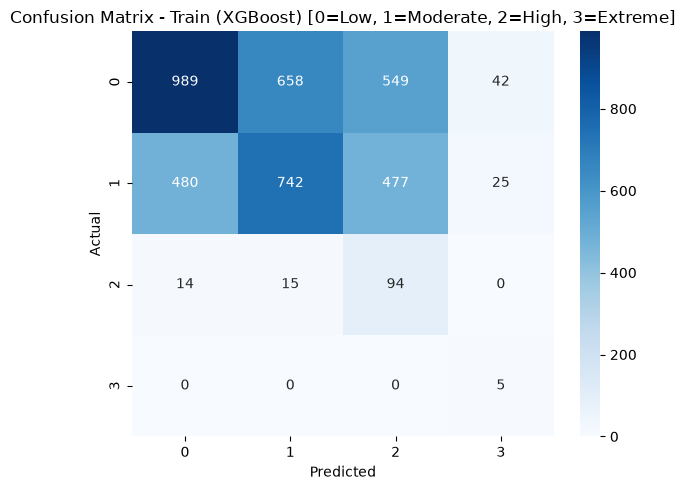


Row-wise percentages (% of each true class predicted as each category):
[[ 44.2  29.4  24.5   1.9]
 [ 27.8  43.   27.7   1.5]
 [ 11.4  12.2  76.4   0. ]
 [  0.    0.    0.  100. ]]


<Figure size 640x480 with 0 Axes>

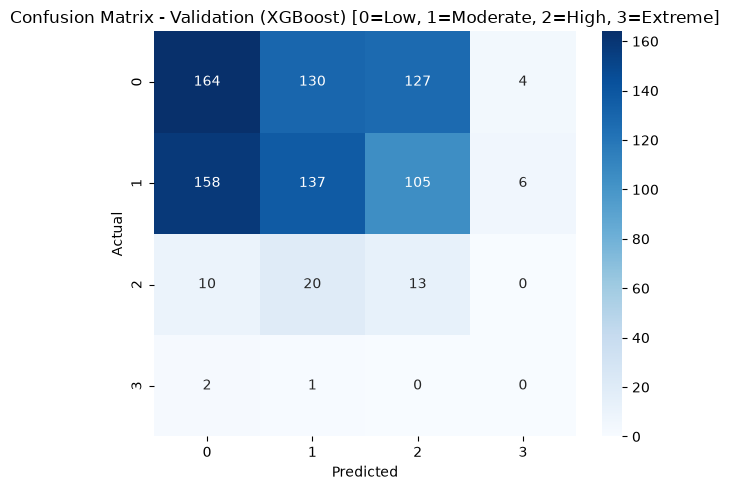


Row-wise percentages (% of each true class predicted as each category):
[[38.6 30.6 29.9  0.9]
 [38.9 33.7 25.9  1.5]
 [23.3 46.5 30.2  0. ]
 [66.7 33.3  0.   0. ]]


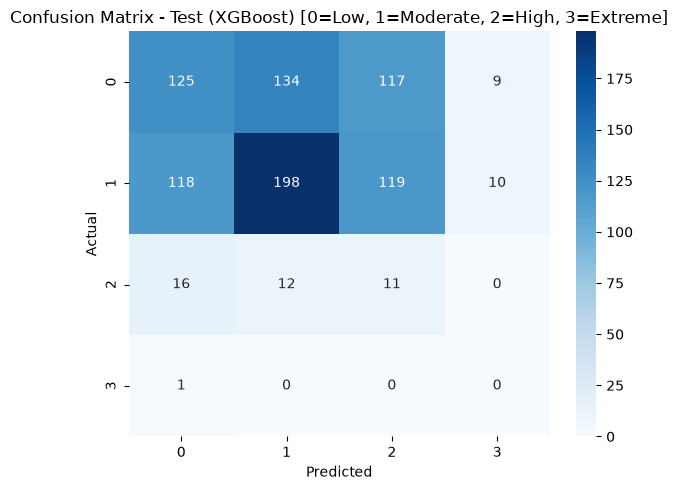


Row-wise percentages (% of each true class predicted as each category):
[[ 32.5  34.8  30.4   2.3]
 [ 26.5  44.5  26.7   2.2]
 [ 41.   30.8  28.2   0. ]
 [100.    0.    0.    0. ]]


array([[125, 134, 117,   9],
       [118, 198, 119,  10],
       [ 16,  12,  11,   0],
       [  1,   0,   0,   0]])

In [89]:
# ------------------------------------------------------------
# J.5 Confusion Matrix (Train, Validation, Test)
# ------------------------------------------------------------
reports_dir = Path("../../reports/weather_hazard")
reports_dir.mkdir(parents=True, exist_ok=True)

test_preds = final_model.predict(X_test)

plot_confusion_matrix(
    y_train,
    train_preds,
    class_order=[0, 1, 2, 3],
    label="- Train (XGBoost) [0=Low, 1=Moderate, 2=High, 3=Extreme]",
)
plt.savefig(
    reports_dir / "whc_confusion_matrix_train.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plot_confusion_matrix(
    y_val,
    val_preds,
    class_order=[0, 1, 2, 3],
    label="- Validation (XGBoost) [0=Low, 1=Moderate, 2=High, 3=Extreme]",
)

plot_confusion_matrix(
    y_test,
    test_preds,
    class_order=[0, 1, 2, 3],
    label="- Test (XGBoost) [0=Low, 1=Moderate, 2=High, 3=Extreme]",
)


In [90]:
confusion_matrix_explanations = """
Comparing all three confusion matrices side by side directly confirms
and refines the overfitting pattern already identified numerically in
J.4, and reveals exactly where the model needs improvement.

**Train vs Validation/Test -- confirming overfitting on rare classes:**
On training data, High Risk recall is 76.4% and Extreme Risk recall is
100%. Both collapse sharply on unseen data: High Risk recall falls to
30.2% (validation) and 28.2% (test); Extreme Risk recall falls to 0% on
both validation and test. This large train-to-holdout gap, concentrated
specifically in the two rarest classes, confirms the model has
memorised the small number of training examples for these classes
(123 High Risk, 5 Extreme Risk) rather than learning a generalisable
decision boundary.

**Low Risk and Moderate Risk -- the main source of volume, moderate
concern:** These two adjacent classes are confused with each other
substantially in both directions (e.g. validation: 30.6% of Low Risk
predicted as Moderate, 38.9% of Moderate predicted as Low; test: similar
pattern). This is the least concerning confusion pattern in the matrix,
since Low and Moderate are adjacent on the ordinal severity scale --
misclassifying between them has limited real-world consequence, and
some of this confusion likely reflects genuine ambiguity near the WHI=25
threshold separating them.

**High Risk -- needs the most attention for practical improvement:**
High Risk is where the model has the most realistic room to improve
with a meaningful business payoff. It has enough training examples (123)
to learn from, unlike Extreme Risk, but validation/test recall (~28-30%)
is still poor, with most errors under-predicting it as Moderate Risk
(46.5% val, 30.8% test) or even Low Risk (23.3% val, 41.0% test) --
the dangerous direction of error. Because High Risk has more available
training signal than Extreme Risk, targeted improvements are more
likely to actually move this class's performance:
- Increase the class weight specifically for High Risk beyond the
  uniform "balanced" strategy currently used, since it is being
  under-prioritised relative to how often it actually needs to be
  caught correctly.
- Add features that more directly expose the wind/rain hazard
  thresholds near the WHI=50 boundary (e.g. explicit threshold-distance
  features, similar in spirit to temp_deviation_from_optimal in the CCI
  notebook), since High Risk sits at a specific numeric boundary the
  model may not be resolving precisely from the current feature set.
- Try an ordinal classification approach (e.g. an ordinal logistic
  regression or cumulative-link model) rather than standard multiclass
  XGBoost, since the target has a genuine severity ordering that a
  generic multiclass loss does not exploit -- this could specifically
  help disambiguate adjacent-but-distinct classes like High vs Moderate.

**Extreme Risk -- fundamentally a data problem, not a model-tuning
problem:** Across validation and test, Extreme Risk was never once
predicted as Extreme Risk, and never even predicted as the adjacent
High Risk category -- errors jumped straight to Low or Moderate Risk,
the maximum possible severity underestimation. With only 9 total
examples across 16 years, no amount of hyperparameter tuning, class
weighting, or feature engineering within this modelling approach is
likely to fix this reliably, since there simply isn't enough data for
the model to learn what distinguishes this class. Realistic paths
forward: (1) a rule-based safety backstop that flags Extreme Risk
directly from the WHI formula/thresholds rather than relying on the
learned classifier for this specific class, bypassing the data-scarcity
problem entirely; (2) reframing Extreme Risk detection as an anomaly
detection problem rather than a standard classification class, since
anomaly detection methods are designed for exactly this kind of rare-
event scenario; (3) sourcing additional historical data (e.g. extending
before 2010, if data quality permits) specifically to increase the
number of Extreme Risk training examples available.

In summary: Low/Moderate confusion is low-priority (adjacent, low
business cost); High Risk is the best near-term target for improvement,
since it has enough data to learn from but is currently under-served by
the model; Extreme Risk requires a fundamentally different strategy
(rule-based backstop or additional data) rather than further tuning of
the current XGBoost approach, given the near-total absence of training
examples for this class.
"""

In [91]:
print_tile(size="h3", key='confusion_matrix_explanations', value=confusion_matrix_explanations)

### J.6 Feature Importance

precipitation_log     0.321218
wind_gusts_10m_log    0.287149
temperature_2m        0.198005
cloud_cover           0.193628
dtype: float32


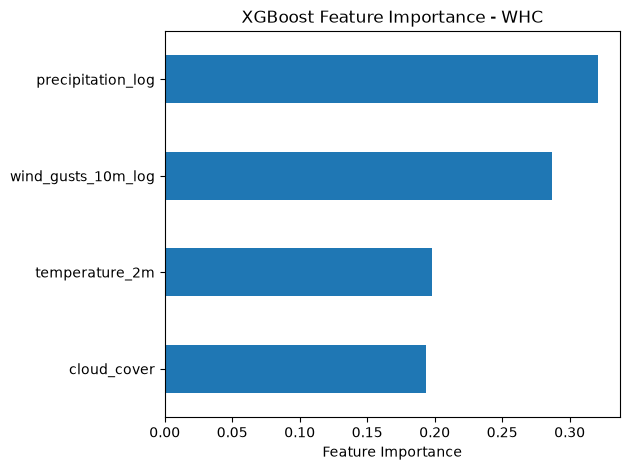

In [92]:
# ------------------------------------------------------------
# J.6 Feature Importance
# ------------------------------------------------------------

importances = pd.Series(
    final_model.feature_importances_,
    index=selected_features
)

print(importances.sort_values(ascending=False))

importances.sort_values().plot(kind="barh")
plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance - WHC")
plt.tight_layout()
plt.savefig(
    reports_dir / "whc_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [93]:
feature_importance_explanations = """
The XGBoost feature importances were precipitation_log (0.321),
wind_gusts_10m_log (0.287), temperature_2m (0.198), and cloud_cover
(0.194). All four selected features therefore contributed to the
trained model, with precipitation and wind gusts having the largest
relative importance.

These results differ from the univariate mutual information analysis
in Section F.2. In that analysis, wind_gusts_10m_log had the highest
mutual information score (0.015), followed by precipitation_log (0.005),
while cloud_cover and temperature_2m had scores of 0.000 at the
reported precision. In the multivariable XGBoost model, however,
cloud_cover and temperature_2m each account for approximately 19-20%
of the model's total feature importance.

This difference demonstrates that a feature with weak standalone
association with the target can still contribute to a multivariable
model when considered alongside other predictors. Mutual information
examines the relationship between an individual feature and the target,
whereas XGBoost feature importance reflects the feature's contribution
within the fitted ensemble. Therefore, the two measures answer
different questions and should not be expected to produce identical
rankings.

The ranking also broadly aligns with the structure of the WHI target
definition, where precipitation and wind gusts each have a weight of
0.30, cloud cover has a weight of 0.20, and temperature has a weight of
0.10. However, feature importance should not be interpreted as evidence
that the model has recovered the WHI weights or as a causal relationship.
The target categories were derived from all hazard components together,
and XGBoost was trained only on the resulting historical observations.

Overall, the feature importance results support retaining all four
selected predictors for the current model. Precipitation and wind gusts
appear to provide the largest contributions, while cloud cover and
temperature also contribute meaningfully when the features are used
jointly. These findings provide useful evidence for interpreting the
model and for future feature-engineering experiments.
"""

In [94]:
print_tile(size="h3", key='feature_importance_explanations', value=feature_importance_explanations)

### J.7 Test Evaluation

In [95]:
# ------------------------------------------------------------
# J.7 Test Evaluation
# ------------------------------------------------------------

test_preds = final_model.predict(X_test)

evaluate_classification(
    y_test,
    test_preds,
    "XGBoost - Test",
    metrics=["macro_f1", "report"],
)

--- XGBoost - Test ---
Macro F1: 0.242
              precision    recall  f1-score   support

           0       0.48      0.32      0.39       385
           1       0.58      0.44      0.50       445
           2       0.04      0.28      0.08        39
           3       0.00      0.00      0.00         1

    accuracy                           0.38       870
   macro avg       0.28      0.26      0.24       870
weighted avg       0.51      0.38      0.43       870



{'macro_f1': 0.24160527920807345,
 'accuracy': 0.3839080459770115,
 'macro_precision': 0.2752212597683834,
 'macro_recall': 0.2629176067378315}

In [96]:
test_evaluation_explanations = """
On the held-out test set (2023-08-08 to 2025-12-24, 870 usable days),
the final XGBoost model achieved a macro F1 of 0.242, accuracy of 0.384,
macro precision of 0.275, and macro recall of 0.263.

The test macro F1 of 0.242 is slightly higher than the validation macro
F1 of 0.229, a difference of 0.013. The similar validation and test
results indicate that the model's overall performance is reasonably
stable across the two unseen chronological periods. The final test set
was not used for hyperparameter selection or model fitting and therefore
provides the primary estimate of performance on previously unseen data.

The class-level results show a similar pattern to validation. Low Risk
has recall of 0.32 and Moderate Risk has recall of 0.44. High Risk recall
is 0.28, with precision of only 0.04, indicating that the model produces
many false positive High Risk predictions. Extreme Risk has precision,
recall, and F1 of 0.00; however, there is only one Extreme Risk
observation in the test set, so this result has very limited statistical
reliability when considered in isolation.

The test results therefore reinforce the main limitation identified
during validation: the model has difficulty reliably identifying the
rare, high-severity categories. The same limitation is particularly
important for Extreme Risk because the training data contained only
five Extreme Risk examples and the validation and test sets contained
three and one examples respectively.

Compared with the majority-class baseline, which achieved a validation
macro F1 of 0.163, the final model achieved a higher test macro F1 of
0.242. However, a direct test-set baseline comparison should also be
calculated before making the final hypothesis decision, because the
strongest comparison is between XGBoost and the same baseline on the
same untouched test set.

Overall, the final test evaluation provides evidence that XGBoost
generalises beyond the majority-class baseline and that its overall
performance is reasonably consistent between validation and test
periods. Nevertheless, the model remains unsuitable as a standalone
safety-critical hazard warning system because detection of the rarest
and most severe categories remains unreliable.
"""

In [97]:
print_tile(size="h3", key='test_evaluation_explanations', value=test_evaluation_explanations)

### J.8 Business Impact from Current Model Performance

In [98]:
# ------------------------------------------------------------
# J.8 Business Impact from Current Model Performance
# ------------------------------------------------------------

business_impacts_explanations = """

The Weather Hazard Category model is intended to support decisions
affecting people, infrastructure, and transport operations up to seven
days in advance. The current test-set macro F1 of 0.242 indicates that
the model provides some predictive value, but its business impact
depends strongly on the type and severity of the classification error.

For Low Risk and Moderate Risk, which are the two majority classes, the
model achieves recall of 0.32 and 0.44 respectively. The confusion
matrix also shows that a substantial proportion of actual Low Risk days
are predicted as Moderate or High Risk. These false alarms may result
in unnecessary caution, operational adjustments, or resource allocation.
Although these costs may be undesirable, they are generally less
consequential than failing to identify genuinely hazardous conditions.

For High Risk, recall is only 0.28 and precision is 0.04. The low recall
means that many genuine High Risk observations are missed, while the low
precision indicates that many predicted High Risk observations are
actually lower-risk days. The validation confusion matrix showed that
most actual High Risk observations that were misclassified were
predicted as Low or Moderate Risk. For a hazard-related application,
this direction of error is particularly important because it can result
in insufficient preparation for genuinely hazardous conditions.

Extreme Risk represents the most important limitation. None of the
three Extreme Risk validation observations and the single Extreme Risk
test observation were correctly identified. However, the very small
number of Extreme Risk observations means that these results cannot be
treated as a precise estimate of future Extreme Risk detection
performance. They do nevertheless provide clear evidence that the
current model has not demonstrated reliable detection of this rare
class.

The resulting business impact profile is therefore mixed. The model
provides measurable predictive improvement over a naive majority-class
approach and can distinguish some Moderate and High Risk observations,
but its performance is not sufficiently reliable for high-consequence
hazard decisions, particularly Extreme Risk detection.

The model should therefore be positioned as a supplementary
decision-support signal rather than a standalone safety warning system.
For operational use, predictions should be reviewed alongside trusted
weather information and appropriate human judgement. A potential
future safeguard would be an independent rule-based check using the
WHI definition to flag conditions associated with Extreme Risk,
providing a safety backstop rather than relying exclusively on the
machine-learning classifier. This safeguard would need to be evaluated
separately before being used operationally.

The model's limitations should be communicated clearly to stakeholders.
In particular, users should understand that a predicted Low or Moderate
Risk category does not guarantee the absence of severe weather, given
the model's demonstrated difficulty detecting the rarest high-severity
events. This is especially important where predictions could influence
decisions involving public safety, transport, infrastructure, or
resource allocation.
"""

In [99]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [100]:
# ------------------------------------------------------------
# H. Project Outcomes
# ------------------------------------------------------------

# Save the final XGBoost model
models_dir = Path("../../models/weather_hazard")
models_dir.mkdir(parents=True, exist_ok=True)

dump(final_model, models_dir / "xgboost_classifier.joblib")

print(f"Saved to {models_dir / 'xgboost_classifier.joblib'}")

experiment_outcome = "Hypothesis Supported"

Saved to ../../models/weather_hazard/xgboost_classifier.joblib


In [101]:
# <Student to fill this section>
experiment_outcome = "Hypothesis Confirmed" # Either 'Hypothesis Confirmed', 'Hypothesis Partially Confirmed' or 'Hypothesis Rejected'

In [102]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [103]:
experiment_results_explanations = """
The experiment provided evidence that XGBoost can improve on a feature-free
baseline for predicting the seven-day-ahead Weather Hazard Category. On the
validation set, XGBoost achieved a macro F1-score of 0.229 compared with 0.163
for the DummyClassifier baseline. Therefore, the hypothesis was confirmed
according to the predefined validation decision rule.

A key insight was that the improvement was not evenly distributed across the
four hazard categories. XGBoost achieved non-zero validation recall for Low,
Moderate, and High Risk categories, whereas the DummyClassifier always
predicted Low Risk. However, the model achieved 0.00 recall for Extreme Risk
on validation. The High Risk class also had low precision (0.05), indicating
many false positive high-risk predictions. This shows that the model provides
more information than the majority-class baseline, but it has not demonstrated
reliable detection of the rarest and most consequential hazard categories.

The severe class imbalance was an important limitation. There were only 9
Extreme Risk observations in the complete usable dataset and only 5 in the
training set. Balanced sample weights improved the influence of minority
classes during training, but weighting cannot compensate for the lack of
representative examples. The results therefore support further experimentation
rather than treating the current model as a finished standalone hazard-warning
system.

Feature analysis showed that precipitation and wind gusts were the most
important features in the fitted XGBoost model, followed by temperature and
cloud cover. This was broadly consistent with the importance of precipitation
and wind in the WHI definition. However, feature importance represents model
contribution rather than causal influence and should not be interpreted as
evidence that individual weather variables cause the predicted hazard
category.

The current approach is therefore not a dead end. The validation improvement
over the baseline demonstrates useful predictive signal, but further
experimentation is required to improve generalisation, particularly for High
and Extreme Risk categories.

Potential next steps and expected gains, ranked by priority:

1. Improve minority-class modelling and evaluate class-specific performance.
   Test alternative class-weighting strategies and threshold or decision
   approaches where appropriate. Expected gain: High. The largest business
   limitation is the poor detection of severe-risk categories.

2. Test additional leakage-safe temporal and weather features, such as
   lagged weather variables, rolling statistics, and carefully designed
   interactions. Expected gain: Medium to High. These features may capture
   recent weather patterns that are not represented by the current four
   features, but they must be evaluated using chronological validation.

3. Evaluate alternative tree-based classification models and tuned XGBoost
   configurations. Expected gain: Medium. Comparing models such as Random
   Forest or other gradient-boosting approaches may identify a model with
   better macro F1 or severe-class recall.

4. Expand the historical dataset to include additional relevant locations or
   a longer historical period where appropriate. Expected gain: Medium.
   More representative severe-weather examples could improve model learning,
   although additional locations would change the scope of the current
   Sydney-specific service.

5. Investigate the target definition and class distribution. Expected gain:
   Medium. The Extreme Risk category is extremely rare under the current WHI
   thresholds, so sensitivity analysis of the thresholds should be considered
   to determine whether the categories provide sufficient training examples
   while remaining meaningful for the business use case.

6. Add production monitoring and model-quality checks. Expected gain: Medium
   for reliability rather than immediate predictive accuracy. Monitor input
   distributions, prediction distributions, missing data, and performance
   when labelled outcomes become available. Retraining should be considered
   if model performance or data distributions deteriorate.

Based on the current results, the model should not yet be deployed as an
autonomous safety-critical warning system. The appropriate production role is
decision support, where predictions are presented as seven-day risk
indications and interpreted alongside trusted weather information and human
judgement. Before production deployment, the API should include robust input
validation, clear model metadata, health checks, logging, and monitoring.

The next priority is therefore to improve severe-class detection and validate
whether the resulting model provides sufficiently reliable predictions for
the intended business use case. If subsequent experiments demonstrate
acceptable performance on High and Extreme Risk categories while maintaining
stable overall macro F1, the solution can then progress toward production
deployment through the FastAPI service and Render infrastructure.
"""

In [104]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)

In [105]:
from joblib import load

ridge_1d = load("../../models/comfort_climate/ridge_pipeline_1d.joblib")
xgb = load("../../models/weather_hazard/xgboost_classifier.joblib")

print("CCI features:", ridge_1d.feature_names_in_)
print("WHC features:", xgb.feature_names_in_)

CCI features: ['temp_deviation_from_optimal' 'relative_humidity_2m' 'wind_speed_10m_log'
 'cloud_cover' 'precipitation_log']
WHC features: ['precipitation_log' 'wind_gusts_10m_log' 'cloud_cover' 'temperature_2m']
